## Overview

This week you will be forecasting the incidence of COVID-19 cases. However, before forecasting you will begin by investigating the relationship between diabetes prevalence and COVID-19 incidence. 

This is split up into three notebooks

  1. Inspect correlations between diabetes and COVID-19 prevelance

  2. Implement LSTM model for COVID-19 forecasting and evaluate on state-level and county-level data.

  3. Visualize the performance of LSTM models trained on nation-level (pretrained), state-level, and county-level data. In addition, we will also visualize the performance of the ARIMA model (pretrained) using county-level data.

## <font color='magenta'>Task One A</font>

In this notebook you will implement elements of the model explained in the paper: [A spatiotemporal machine learning approach to forecasting
COVID-19 incidence at the county level in the United States](https://arxiv.org/pdf/2109.12094.pdf).

In particular, you must fill in the following functions in ```find_best_hyperparameters```

- `QuantileLoss` 
  - `__init__` 
  - `forward`
  
- `LSTM` 
  - `__init__` 
  - `forward`
  
Unlike the paper you will not be implementing an ensemble but only one model (this is only to save time, we do encourage you to explore ensemble models on your own). 

You will need the constants below so do not change these:

In [1]:
import warnings
warnings.simplefilter("ignore")

import pandas as pd
import numpy as np

import sys
import os
from mads.lib.path import assets

data_cleaners = assets.find("shared_files/assignment4/data_cleaners.py")
sys.path.append(os.path.dirname(data_cleaners))
import data_cleaners as dc

find_best_hyperparameters = assets.find("shared_files/assignment4/find_best_hyperparameters.py")
sys.path.append(os.path.dirname(find_best_hyperparameters))
import find_best_hyperparameters as fbh

STATE = 'Wisconsin'
COUNTY = 'Milwaukee'
BURNIN_WEEKS = 14 # after INITIAL_DATE
NUM_BIWEEKLY_INTERVALS = 20 # after the burnin period

***NOTE that the training time for every interval will gradually increase as the number of training samples increase. 
It takes less than 5 minutes to complete. Please check your code if it is taking longer than 5 minutes to complete.***

The first row of err_results_df (Pandas dataframe) is shown below:

|    |   error(State) |   error(County) | forecast_dates   |
|---:|---------------:|----------------:|:-----------------|
|  0 |      1046.15   |        953.033  | 2020-07-12       |

final_results_state is a list of Pandas dataframes. The first row of the first item in the list is shown below:

|    |   GEOID |   q_25_pred |   q_100_pred |   q_250_pred |   q_500_pred |   q_750_pred |   q_900_pred |   q_975_pred |   q_25_err |   q_100_err |   q_250_err |    q_500_err |   q_750_err |   q_900_err |   q_975_err |   y_label |   y_delta_cases |   q_25_pred_transform |   q_25_pred_cases |   q_100_pred_transform |   q_100_pred_cases |   q_250_pred_transform |   q_250_pred_cases |   q_500_pred_transform |   q_500_pred_cases |   q_750_pred_transform |   q_750_pred_cases |   q_900_pred_transform |   q_900_pred_cases |   q_975_pred_transform |   q_975_pred_cases |   y_lbl_transform |   y_label_transformed |   y_q500_err |
|---:|--------:|------------:|-------------:|-------------:|-------------:|-------------:|-------------:|-------------:|-----------:|------------:|------------:|-------------:|------------:|------------:|------------:|----------:|----------------:|----------------------:|------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|------------------:|----------------------:|-------------:|
|  0 |   55001 |  0.635589   |    1.00267   |     1.28862  |     1.79157  |     2.11468  |      2.27235 |      2.59408 |  1.19875   |   0.831668  |    0.54572  |  0.0427656   | -0.280339   | -0.438008   |  -0.759739  |  1.83434  |              14 |            0.888134   |         1.78462   |              1.72555   |          3.46732   |               2.62777  |           5.28024  |               4.99888  |          10.0447   |                7.28691 |           14.6423  |                8.70214 |           17.4861  |               12.3842  |           24.8849  |          5.26099  |             10.5714   |     3.95526  |

Similarly, final_results_county is a list of Pandas dataframes. The first row of the first item in the list is shown below:

|    |   GEOID |   q_25_pred |   q_100_pred |   q_250_pred |   q_500_pred |   q_750_pred |   q_900_pred |   q_975_pred |   q_25_err |   q_100_err |   q_250_err |   q_500_err |   q_750_err |   q_900_err |   q_975_err |   y_label |   y_delta_cases |   q_25_pred_transform |   q_25_pred_cases |   q_100_pred_transform |   q_100_pred_cases |   q_250_pred_transform |   q_250_pred_cases |   q_500_pred_transform |   q_500_pred_cases |   q_750_pred_transform |   q_750_pred_cases |   q_900_pred_transform |   q_900_pred_cases |   q_975_pred_transform |   q_975_pred_cases |   y_lbl_transform |   y_label_transformed |   y_q500_err |
|---:|--------:|------------:|-------------:|-------------:|-------------:|-------------:|-------------:|-------------:|-----------:|------------:|------------:|------------:|------------:|------------:|------------:|----------:|----------------:|----------------------:|------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|-----------------------:|-------------------:|------------------:|----------------------:|-------------:|
|  0 |   55079 |      1.8511 |     0.980312 |     0.764299 |      2.45973 |      2.13678 |      1.54987 |      2.84166 |    1.19097 |     2.06176 |     2.27778 |    0.582348 |      0.9053 |     1.49221 |    0.200421 |   3.04208 |            1971 |               5.36683 |           510.507 |                1.66529 |            158.407 |                1.14749 |            109.152 |                10.7016 |            1017.97 |                7.47208 |            710.764 |                3.71084 |            352.985 |                16.1441 |            1535.67 |           19.9487 |               1897.57 |      953.033 |


In [2]:
# after adding code to QuantileLoss and LSTM as instructed above,
# comment out the blank return statement in eval_results() before running this cell. 
err_results_df, final_results_state, final_results_county = fbh.eval_results(BURNIN_WEEKS,
                                                                             NUM_BIWEEKLY_INTERVALS,
                                                                             STATE,
                                                                             COUNTY,
                                                                             dc.TEMPORAL_LAG,
                                                                             dc.FORECAST_HORIZON
                                                                            )

Training for 20 intervals...
Training interval 1 for 2020-07-12 with 360 train samples (state)
Training interval 1 for 2020-07-12 with 5 train samples (county)
Training interval 6 for 2020-09-20 with 1080 train samples (state)
Training interval 6 for 2020-09-20 with 15 train samples (county)
Training interval 11 for 2020-11-29 with 1800 train samples (state)
Training interval 11 for 2020-11-29 with 25 train samples (county)
Training interval 16 for 2021-02-07 with 2520 train samples (state)
Training interval 16 for 2021-02-07 with 35 train samples (county)
Training interval 20 for 2021-04-04 with 3096 train samples (state)
Training interval 20 for 2021-04-04 with 43 train samples (county)


In [3]:
#hidden tests are within this cell

## <font color='magenta'>Task One B</font>

We have run the same model you implemented for the Milwaukee county in the state of Wisconsin.

Using the results from the previous task, generate the plot showing the predicted (50th quantile), actual number of cases, and the range between the 2.5th quantile and the 97.5th quantile. We will use the data from the **state level LSTM model**. 

You will need to recreate the plot shown below.

TIPS -
- Check out pyplot fill_between command to create shading for plotting the range of values between the 2.5th quantile and the 97.5th quantile.
- FIPS/GEOID for Milwaukee county is 55079.

Note:
  - the hex color for the predicted new cases is: #1b9e77
  - the hex color for the actual new cases is: #66a61e
  - the color for the fill_between is: lightblue

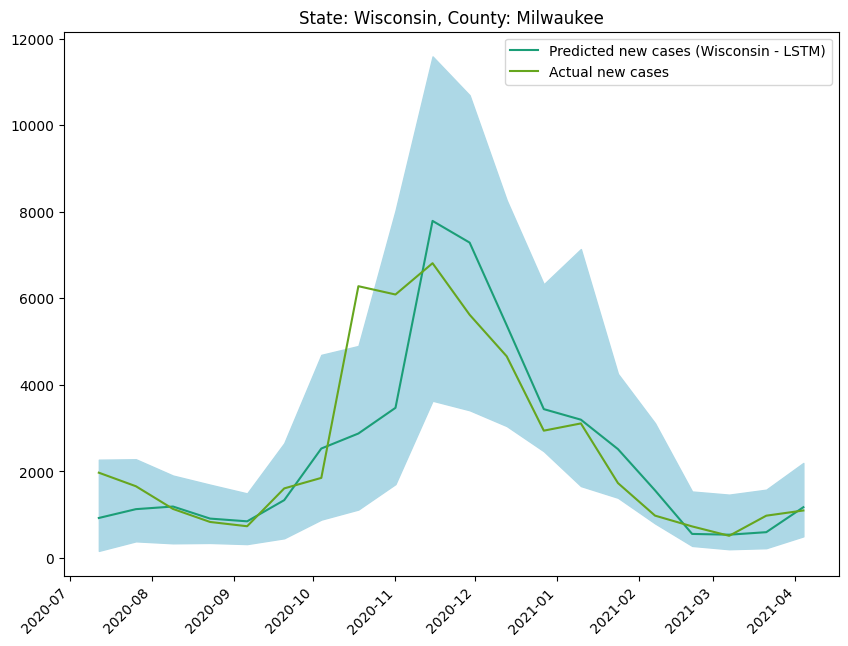

In [4]:
# Generate the plot showing the predicted (50th quantile), actual number of cases, and the range
# between the 2.5th quantile and the 97.5th quantile for the county with data from the state level LSTM model.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# take the Milwaukee row from each state-model forecast
milwaukee_forecasts = pd.concat(
    [frame.loc[frame["GEOID"].eq(55079)] for frame in final_results_state],
    ignore_index=True,
)
forecast_dates = pd.to_datetime(err_results_df["forecast_dates"])

fig, ax = plt.subplots(figsize=(10, 8))

# shade the interval between the 2.5th and 97.5th percentiles
ax.fill_between(
    forecast_dates,
    milwaukee_forecasts["q_25_pred_cases"].to_numpy(),
    milwaukee_forecasts["q_975_pred_cases"].to_numpy(),
    color="lightblue",
)

# plot the median forecast and observed new cases
ax.plot(
    forecast_dates,
    milwaukee_forecasts["q_500_pred_cases"],
    color="#1b9e77",
    label="Predicted new cases (Wisconsin - LSTM)",
)
ax.plot(
    forecast_dates,
    milwaukee_forecasts["y_delta_cases"],
    color="#66a61e",
    label="Actual new cases",
)

ax.set_title("State: Wisconsin, County: Milwaukee")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.legend()
fig.autofmt_xdate(rotation=45)
plt.show()

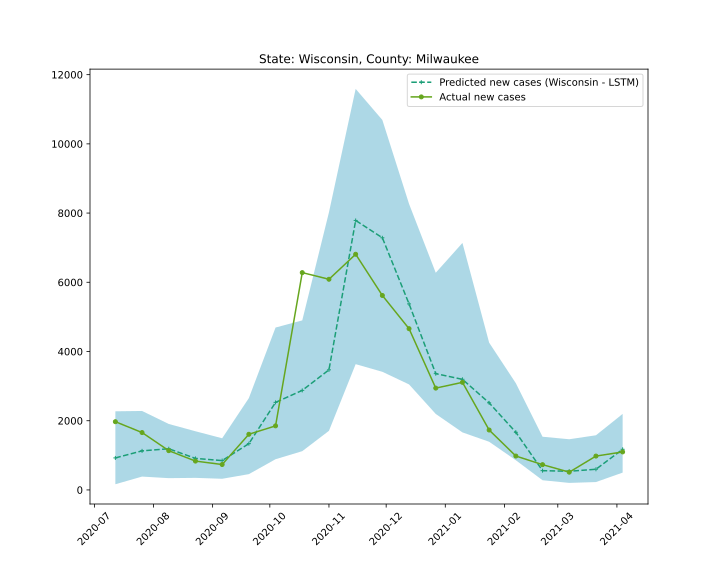

In [5]:
from IPython.display import SVG, display
def show_svg():
    display(SVG(filename=assets.find("assignment4/milwaukie_predicted_cases.svg")))
show_svg()

## <font color='magenta'>Task One C</font>

Answer the following questions:
    
    When is the prediction interval the widest (to enter your answer, answer it as the closest x-tick)?


In [6]:
# report the closest labeled month on the reference plot
widest_interval = "2020-11"

In [7]:
#hidden tests are within this cell

## IMPORTANT: Uncomment the following code when you are ready to move on to the next assignment

In [8]:
script = assets.find('copy_shared_files.sh')
!bash {script}

=== Copying shared files back to coursework ===
✅ Shared files successfully copied back to coursework.
